# Tugas 1 - Prediksi Customer Churn dengan Artificial Neural Network (TensorFlow / Keras)

| Nama | NRP |
|------|-----|
| Muhammad Nazwar Fakhrurrozy | 5054251040 |

## Deskripsi Tugas
Pada tugas ini, kita akan menggunakan Churn Modelling Dataset. Dataset bisa diakses melalui link berikut:\
https://www.kaggle.com/datasets/shrutimechlearn/churn-modelling

Dataset berisi data 10.000 nasabah bank, seperti skor kredit, negara, usia, saldo, dan status keaktifan. Tujuan utama dari tugas ini adalah membangun model Artificial Neural Network (ANN) menggunakan **TensorFlow / Keras** untuk memprediksi apakah seorang nasabah akan berhenti menjadi nasabah (churn, kolom `Exited`) atau tidak.

Langkah-langkah yang harus dilakukan antara lain:
1. Persiapan Dataset dan Eksplorasi Awal
   - Memuat dataset, melihat struktur data, dan distribusi label.
2. Preprocessing
   - Memproses data agar siap digunakan oleh ANN.
3. Eksperimen Model
   - Bangun model baseline Logistic Regression dan beberapa konfigurasi ANN.
4. Evaluasi Model
   - Hitung metrik evaluasi dan visualisasikan hasilnya.
5. Analisis dan Kesimpulan
   - Bandingkan hasil seluruh model dan berikan kesimpulan.

# 1. Persiapan Dataset dan Eksplorasi Awal

In [72]:
# Import library yang dibutuhkan (pandas, numpy, matplotlib, seaborn, sklearn, tensorflow, dll).
# Set random seed agar hasil eksperimen dapat direproduksi, gunakan tf.keras.utils.set_random_seed(42).
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, roc_curve, auc
from sklearn.utils.class_weight import compute_class_weight

tf.keras.utils.set_random_seed(42)

In [73]:
# Load dataset dan tampilkan beberapa baris pertama.
# Tampilkan informasi dasar: jumlah baris dan kolom, tipe data, statistik deskriptif, dan jumlah missing value.
df = pd.read_csv("Churn_Modelling.csv")
print(df.head())
print(df.shape)
df.info()
print(df.describe())
print(df.isnull().sum())

   RowNumber  CustomerId   Surname  CreditScore Geography  Gender  Age  \
0          1    15634602  Hargrave          619    France  Female   42   
1          2    15647311      Hill          608     Spain  Female   41   
2          3    15619304      Onio          502    France  Female   42   
3          4    15701354      Boni          699    France  Female   39   
4          5    15737888  Mitchell          850     Spain  Female   43   

   Tenure    Balance  NumOfProducts  HasCrCard  IsActiveMember  \
0       2       0.00              1          1               1   
1       1   83807.86              1          0               1   
2       8  159660.80              3          1               0   
3       1       0.00              2          0               0   
4       2  125510.82              1          1               1   

   EstimatedSalary  Exited  
0        101348.88       1  
1        112542.58       0  
2        113931.57       1  
3         93826.63       0  
4         790

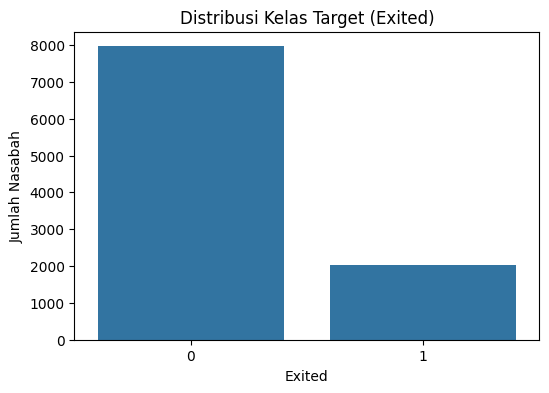

In [74]:
# Tampilkan distribusi kelas target (Exited) dalam bentuk bar plot.
# Perhatikan apakah dataset ini imbalanced.
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x="Exited")
plt.title("Distribusi Kelas Target (Exited)")
plt.xlabel("Exited")
plt.ylabel("Jumlah Nasabah")
plt.show()

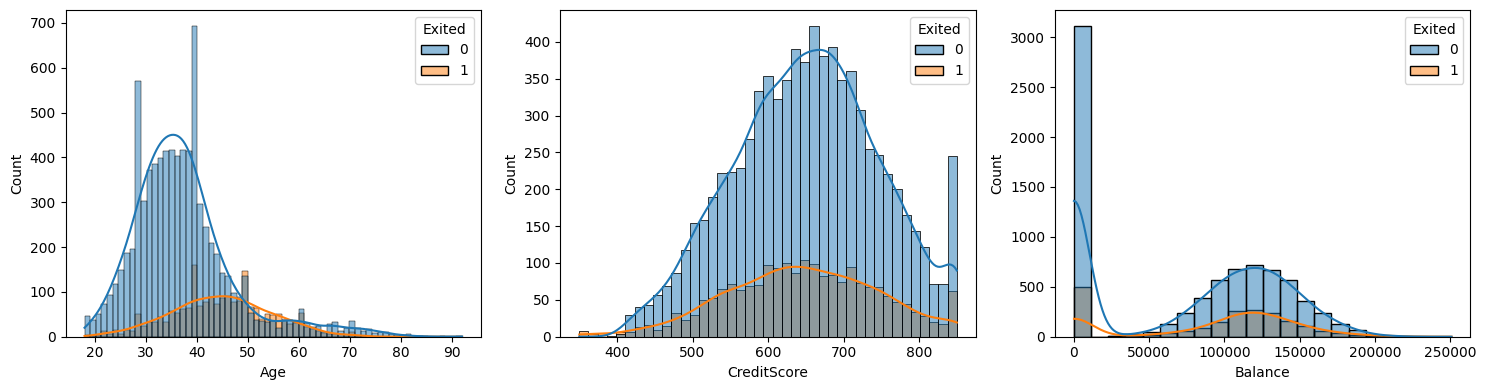

In [75]:
# Tampilkan distribusi fitur numerik (misalnya Age, CreditScore, Balance) menggunakan histogram atau KDE plot, dibedakan berdasarkan kelas Exited.
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
sns.histplot(data=df, x="Age", hue="Exited", kde=True, ax=axes[0])
sns.histplot(data=df, x="CreditScore", hue="Exited", kde=True, ax=axes[1])
sns.histplot(data=df, x="Balance", hue="Exited", kde=True, ax=axes[2])
plt.tight_layout()
plt.show()

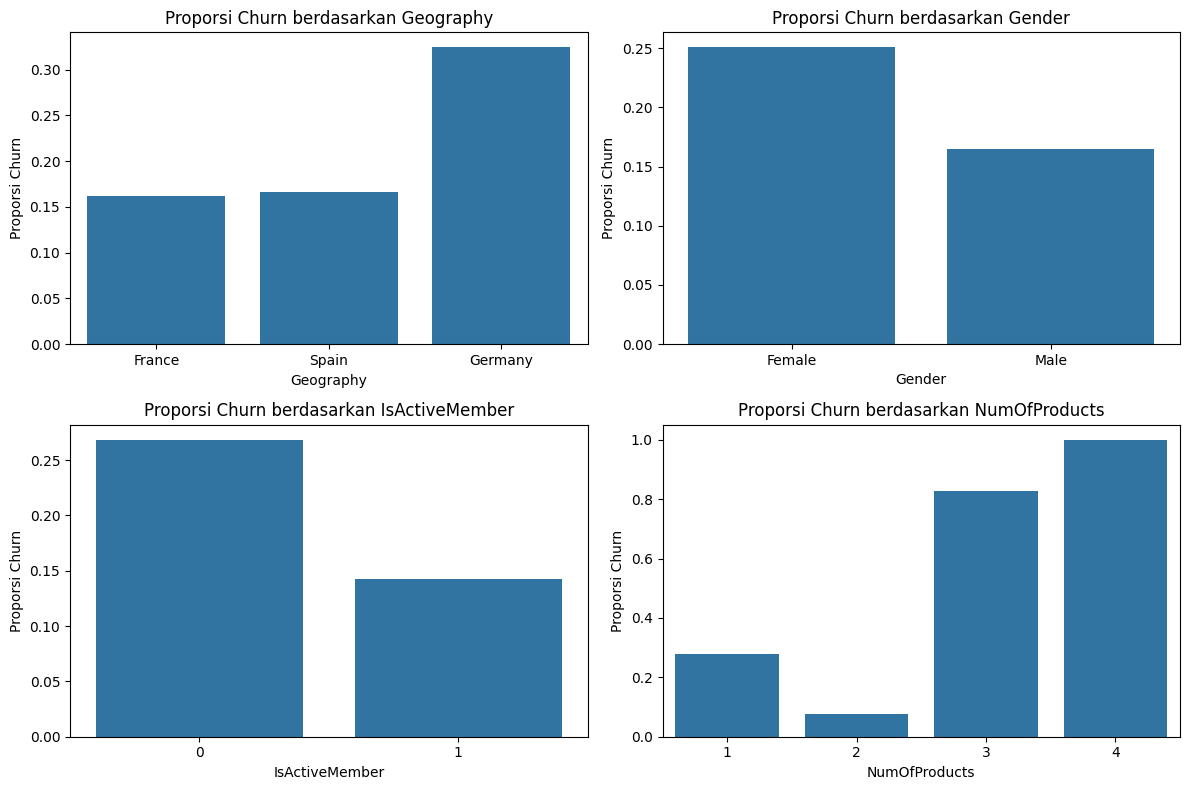

In [76]:
# Tampilkan proporsi churn untuk setiap kategori pada fitur kategorikal (Geography, Gender, IsActiveMember, NumOfProducts).
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
cat_cols = ["Geography", "Gender", "IsActiveMember", "NumOfProducts"]

for i, col in enumerate(cat_cols):
    ax = axes[i // 2, i % 2]
    sns.barplot(data=df, x=col, y="Exited", errorbar=None, ax=ax)
    ax.set_title(f"Proporsi Churn berdasarkan {col}")
    ax.set_ylabel("Proporsi Churn")

plt.tight_layout()
plt.show()

## Lakukan Exploratory Data Analysis (EDA) tambahan yang diperlukan.

# 2. Preprocessing

ANN hanya menerima input numerik dan sangat sensitif terhadap skala fitur. Perhatikan jenis setiap kolom sebelum memilih preprocessing:

| Jenis kolom | Contoh | Preprocessing |
|---|---|---|
| Identitas (tidak informatif) | RowNumber, CustomerId, Surname | Drop |
| Kategorikal nominal | Geography | OneHotEncoder |
| Kategorikal biner | Gender | Encode menjadi 0/1 |
| Numerik | CreditScore, Age, Balance, dll. | StandardScaler |

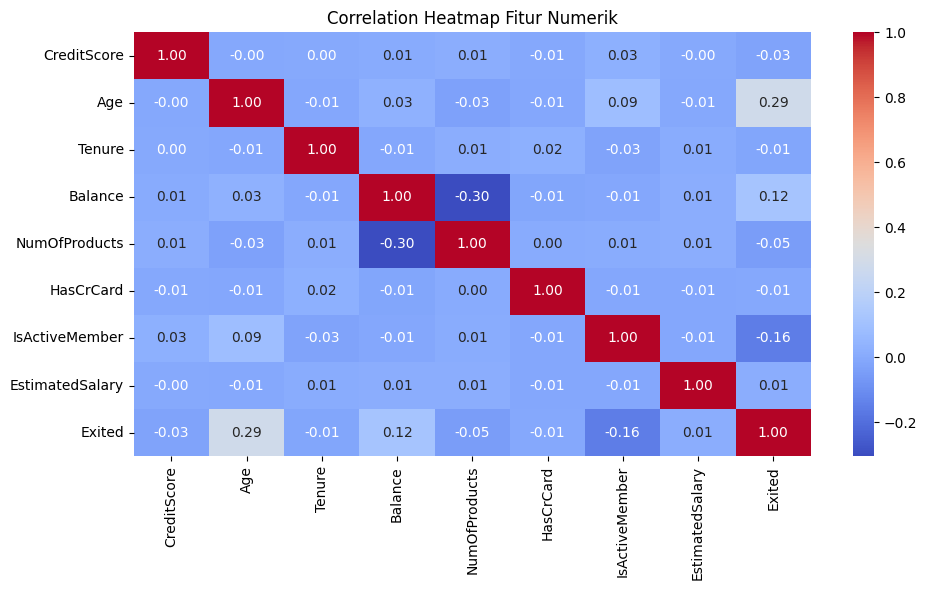

In [77]:
plt.figure(figsize=(10, 6))
numeric_df = df.drop(columns=["RowNumber", "CustomerId", "Surname", "Geography", "Gender"])
sns.heatmap(numeric_df.corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Correlation Heatmap Fitur Numerik")
plt.tight_layout()
plt.show()

In [78]:
# Drop kolom yang tidak relevan untuk prediksi.
# Jelaskan secara singkat (dalam komentar) alasan kolom tersebut di-drop.
df = df.drop(columns=["RowNumber", "CustomerId", "Surname"])
# Kolom RowNumber, CustomerId, dan Surname di drop karena merupakan identitas unik nasabah yang bersifat acak/spesifik individu dan tidak memiliki pola hubungan statistik terhadap kecenderungan nasabah untuk churn (Exited)

In [79]:
# Pisahkan fitur (X) dan target (y).
# Bagi data menjadi train set, validation set, dan test set (misalnya 70:15:15).
# Gunakan stratify=y agar distribusi kelas tetap proporsional di setiap set.
# Validation set digunakan untuk memantau training (learning curve), test set hanya digunakan untuk evaluasi akhir.
X = df.drop(columns=["Exited"])
y = df["Exited"]

X_train_val, X_test, y_train_val, y_test = train_test_split(
    X, y, test_size=0.15, random_state=42, stratify=y
)

X_train, X_val, y_train, y_val = train_test_split(
    X_train_val, y_train_val, test_size=15/85, random_state=42, stratify=y_train_val
)

In [80]:
# Lakukan encoding pada fitur kategorikal dan scaling pada fitur numerik.
# Fit encoder dan scaler hanya pada train set, kemudian transform pada train, validation, dan test set.
# Disarankan menggunakan ColumnTransformer agar rapi.
num_cols = ["CreditScore", "Age", "Tenure", "Balance", "NumOfProducts", "HasCrCard", "IsActiveMember", "EstimatedSalary"]
cat_cols = ["Geography", "Gender"]

preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), num_cols),
        ("cat", OneHotEncoder(drop="first", handle_unknown="ignore"), cat_cols)
    ]
)

X_train_prep = preprocessor.fit_transform(X_train)
X_val_prep = preprocessor.transform(X_val)
X_test_prep = preprocessor.transform(X_test)

In [81]:
# Pastikan X dan y untuk train, validation, dan test berupa numpy array bertipe float32.
# Contoh: X_train = np.asarray(X_train, dtype="float32")
X_train = np.asarray(X_train_prep, dtype="float32")
X_val = np.asarray(X_val_prep, dtype="float32")
X_test = np.asarray(X_test_prep, dtype="float32")

y_train = np.asarray(y_train, dtype="float32")
y_val = np.asarray(y_val, dtype="float32")
y_test = np.asarray(y_test, dtype="float32")

# 3. Eksperimen Model

## 3.1 Baseline: Logistic Regression

Sebelum membangun ANN, buat model sederhana sebagai pembanding. Model yang lebih kompleks hanya layak digunakan jika performanya lebih baik dari baseline.

In [82]:
# Inisialisasi dan latih model Logistic Regression (sklearn) menggunakan train set.
# Lakukan prediksi pada test set, simpan hasil prediksi label dan probabilitas kelas 1.
lr_model = LogisticRegression(random_state=42)
lr_model.fit(X_train, y_train)

y_pred_proba_lr = lr_model.predict_proba(X_test)[:, 1]
y_pred_lr = (y_pred_proba_lr >= 0.5).astype(int)

## 3.2 ANN Sederhana

Bangun ANN dengan **1 hidden layer**. Karena ini klasifikasi biner, gunakan **1 neuron output dengan aktivasi Sigmoid** dan **Binary Cross-Entropy** sebagai loss function.

Contoh arsitektur: `Input → Dense(16, ReLU) → Dense(1, Sigmoid)`

In [83]:
# Definisikan arsitektur ANN sederhana menggunakan keras.Sequential.
# Gunakan keras.Input(shape=(jumlah_fitur,)) sebagai layer pertama, lalu layers.Dense untuk hidden layer dan output layer.
# Tampilkan ringkasan model beserta jumlah parameternya dengan model.summary().
model_simple = tf.keras.Sequential([
    tf.keras.Input(shape=(X_train.shape[1],)),
    tf.keras.layers.Dense(16, activation="relu"),
    tf.keras.layers.Dense(1, activation="sigmoid")
])
model_simple.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_2 (Dense)                 │ (None, 16)             │           192 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 209 (836.00 B)

 Trainable params: 209 (836.00 B)

 Non-trainable params: 0 (0.00 B)

In [84]:
# Compile model: tentukan optimizer (misalnya keras.optimizers.Adam(learning_rate=...)), loss="binary_crossentropy", dan metrics=["accuracy"].
# Latih model dengan model.fit(), gunakan validation_data=(X_val, y_val) agar loss dan accuracy validation tercatat setiap epoch.
# Simpan hasil model.fit() ke variabel history.
model_simple.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

history_simple = model_simple.fit(
    X_train, y_train,
    epochs=50,
    batch_size=32,
    validation_data=(X_val, y_val)
)

Epoch 1/50


219/219 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.6897 - loss: 0.6168 - val_accuracy: 0.7940 - val_loss: 0.5004
Epoch 2/50
219/219 ━━━━━━━━━━━━━━━━━━━━ 0s 876us/step - accuracy: 0.7993 - loss: 0.4626 - val_accuracy: 0.8087 - val_loss: 0.4399
Epoch 3/50
219/219 ━━━━━━━━━━━━━━━━━━━━ 0s 886us/step - accuracy: 0.8126 - loss: 0.4269 - val_accuracy: 0.8167 - val_loss: 0.4189
Epoch 4/50
219/219 ━━━━━━━━━━━━━━━━━━━━ 0s 879us/step - accuracy: 0.8264 - loss: 0.4096 - val_accuracy: 0.8313 - val_loss: 0.4040
Epoch 5/50
219/219 ━━━━━━━━━━━━━━━━━━━━ 0s 881us/step - accuracy: 0.8366 - loss: 0.3954 - val_accuracy: 0.8387 - val_loss: 0.3898
Epoch 6/50
219/219 ━━━━━━━━━━━━━━━━━━━━ 0s 954us/step - accuracy: 0.8414 - loss: 0.3828 - val_accuracy: 0.8493 - val_loss: 0.3775
Epoch 7/50
219/219 ━━━━━━━━━━━━━━━━━━━━ 0s 887us/step - accuracy: 0.8483 - loss: 0.3725 - val_accuracy: 0.8567 - val_loss: 0.3671
Epoch 8/50
219/219 ━━━━━━━━━━━━━━━━━━━━ 0s 947us/step - accuracy: 0.8514 - loss: 0.3645 - val_accuracy:

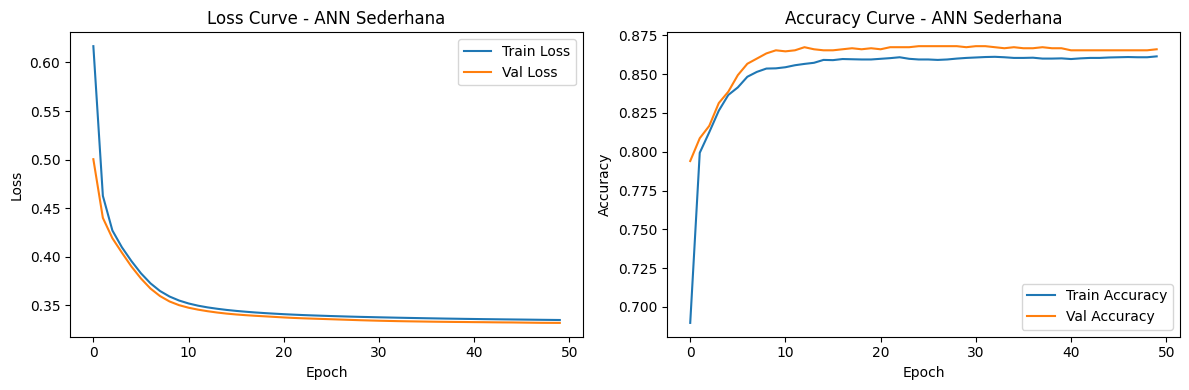

In [85]:
# Tampilkan learning curve (loss dan accuracy) train vs validation dalam bentuk line plot.
# Gunakan history.history["loss"], history.history["val_loss"], history.history["accuracy"], dan history.history["val_accuracy"].
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(history_simple.history["loss"], label="Train Loss")
axes[0].plot(history_simple.history["val_loss"], label="Val Loss")
axes[0].set_title("Loss Curve - ANN Sederhana")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()

axes[1].plot(history_simple.history["accuracy"], label="Train Accuracy")
axes[1].plot(history_simple.history["val_accuracy"], label="Val Accuracy")
axes[1].set_title("Accuracy Curve - ANN Sederhana")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].legend()

plt.tight_layout()
plt.show()

In [86]:
# Lakukan prediksi pada test set dengan model.predict(X_test). Hasilnya berupa probabilitas kelas 1.
# Ubah menjadi label dengan threshold 0.5, lalu simpan probabilitas dan label untuk keperluan evaluasi.
y_pred_proba_simple = model_simple.predict(X_test).ravel()
y_pred_simple = (y_pred_proba_simple >= 0.5).astype(int)

47/47 ━━━━━━━━━━━━━━━━━━━━ 0s 864us/step


## 3.3 ANN Lebih Dalam dengan Dropout

Bangun ANN dengan **2–3 hidden layer** dan tambahkan **Dropout** di antara hidden layer untuk mengurangi overfitting.

In [87]:
# Definisikan arsitektur ANN yang lebih dalam, tambahkan layers.Dropout(rate) di antara hidden layer.
# Tampilkan ringkasan model beserta jumlah parameternya.
model_deep = tf.keras.Sequential([
    tf.keras.Input(shape=(X_train.shape[1],)),
    tf.keras.layers.Dense(32, activation="relu"),
    tf.keras.layers.Dropout(0.2),
    tf.keras.layers.Dense(16, activation="relu"),
    tf.keras.layers.Dropout(0.2),
    tf.keras.layers.Dense(1, activation="sigmoid")
])
model_deep.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_4 (Dense)                 │ (None, 32)             │           384 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 929 (3.63 KB)

 Trainable params: 929 (3.63 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/50
219/219 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.7437 - loss: 0.5526 - val_accuracy: 0.8007 - val_loss: 0.4497
Epoch 2/50
219/219 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8094 - loss: 0.4503 - val_accuracy: 0.8280 - val_loss: 0.4228
Epoch 3/50
219/219 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8147 - loss: 0.4314 - val_accuracy: 0.8347 - val_loss: 0.4080
Epoch 4/50
219/219 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8266 - loss: 0.4215 - val_accuracy: 0.8460 - val_loss: 0.3914
Epoch 5/50
219/219 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8333 - loss: 0.4027 - val_accuracy: 0.8520 - val_loss: 0.3752
Epoch 6/50
219/219 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8411 - loss: 0.3884 - val_accuracy: 0.8627 - val_loss: 0.3597
Epoch 7/50
219/219 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8439 - loss: 0.3796 - val_accuracy: 0.8653 - val_loss: 0.3495
Epoch 8/50
219/219 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8440 - loss: 0.3754 - val_accuracy: 0.

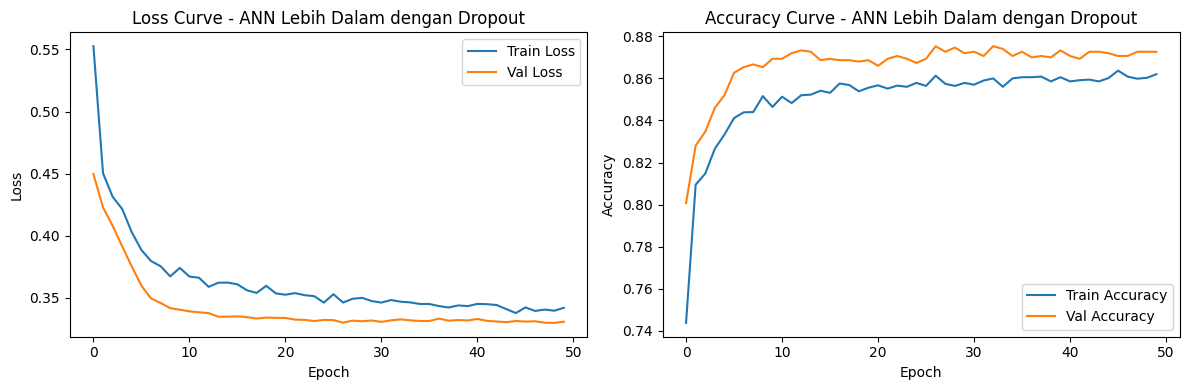

In [ ]:
# Latih model dengan cara yang sama seperti 3.2, lalu tampilkan learning curve train vs validation.
# Bandingkan bentuk learning curve-nya dengan model 3.2. Apakah ada tanda overfitting? Tidak Overfitting
model_deep.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

history_deep = model_deep.fit(
    X_train, y_train,
    epochs=50,
    batch_size=32,
    validation_data=(X_val, y_val)
)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(history_deep.history["loss"], label="Train Loss")
axes[0].plot(history_deep.history["val_loss"], label="Val Loss")
axes[0].set_title("Loss Curve - ANN Lebih Dalam dengan Dropout")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()

axes[1].plot(history_deep.history["accuracy"], label="Train Accuracy")
axes[1].plot(history_deep.history["val_accuracy"], label="Val Accuracy")
axes[1].set_title("Accuracy Curve - ANN Lebih Dalam dengan Dropout")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].legend()

plt.tight_layout()
plt.show()

In [89]:
# Lakukan prediksi pada test set.
# Simpan hasil prediksi label dan probabilitas kelas 1 untuk keperluan evaluasi.
y_pred_proba_deep = model_deep.predict(X_test).ravel()
y_pred_deep = (y_pred_proba_deep >= 0.5).astype(int)

47/47 ━━━━━━━━━━━━━━━━━━━━ 0s 921us/step


## 3.4 Penanganan Data Imbalanced

Pada data imbalanced, model cenderung lebih sering memprediksi kelas mayoritas sehingga recall kelas churn rendah. Salah satu cara mengatasinya adalah dengan memberi bobot lebih besar pada kelas minoritas di loss function.

In [90]:
# Gunakan arsitektur terbaik dari 3.2 atau 3.3 (buat ulang modelnya agar bobot mulai dari awal), lalu latih dengan class weight.
# Hitung bobot setiap kelas berdasarkan train set, misalnya dengan sklearn.utils.class_weight.compute_class_weight("balanced", ...).
# Masukkan ke model.fit() melalui parameter class_weight={0: bobot_kelas_0, 1: bobot_kelas_1}.
classes = np.unique(y_train)
weights = compute_class_weight(class_weight="balanced", classes=classes, y=y_train)
class_weights_dict = dict(zip(classes, weights))

model_cw = tf.keras.Sequential([
    tf.keras.Input(shape=(X_train.shape[1],)),
    tf.keras.layers.Dense(32, activation="relu"),
    tf.keras.layers.Dropout(0.2),
    tf.keras.layers.Dense(16, activation="relu"),
    tf.keras.layers.Dropout(0.2),
    tf.keras.layers.Dense(1, activation="sigmoid")
])

model_cw.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

history_cw = model_cw.fit(
    X_train, y_train,
    epochs=50,
    batch_size=32,
    validation_data=(X_val, y_val),
    class_weight=class_weights_dict
)

Epoch 1/50
219/219 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.6613 - loss: 0.6519 - val_accuracy: 0.7073 - val_loss: 0.5958
Epoch 2/50
219/219 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.6971 - loss: 0.5924 - val_accuracy: 0.6993 - val_loss: 0.5641
Epoch 3/50
219/219 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.7183 - loss: 0.5593 - val_accuracy: 0.7240 - val_loss: 0.5303
Epoch 4/50
219/219 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.7291 - loss: 0.5400 - val_accuracy: 0.7280 - val_loss: 0.5183
Epoch 5/50
219/219 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.7481 - loss: 0.5215 - val_accuracy: 0.7553 - val_loss: 0.4974
Epoch 6/50
219/219 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.7503 - loss: 0.5153 - val_accuracy: 0.7600 - val_loss: 0.4905
Epoch 7/50
219/219 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.7576 - loss: 0.5102 - val_accuracy: 0.7700 - val_loss: 0.4790
Epoch 8/50
219/219 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.7607 - loss: 0.5061 - val_accuracy: 0.

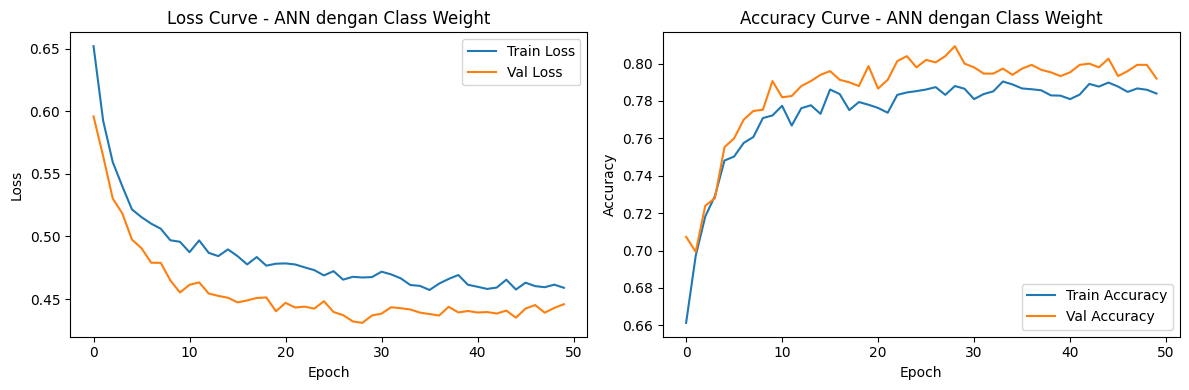

47/47 ━━━━━━━━━━━━━━━━━━━━ 0s 918us/step


In [91]:
# Tampilkan learning curve train vs validation.
# Lakukan prediksi pada test set, simpan hasil prediksi label dan probabilitas kelas 1.
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(history_cw.history["loss"], label="Train Loss")
axes[0].plot(history_cw.history["val_loss"], label="Val Loss")
axes[0].set_title("Loss Curve - ANN dengan Class Weight")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()

axes[1].plot(history_cw.history["accuracy"], label="Train Accuracy")
axes[1].plot(history_cw.history["val_accuracy"], label="Val Accuracy")
axes[1].set_title("Accuracy Curve - ANN dengan Class Weight")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].legend()

plt.tight_layout()
plt.show()

y_pred_proba_cw = model_cw.predict(X_test).ravel()
y_pred_cw = (y_pred_proba_cw >= 0.5).astype(int)

# 4. Evaluasi Model

In [95]:
# Tampilkan metrik evaluasi untuk setiap model: Accuracy, Precision, Recall, dan F1-Score.
# Sajikan dalam satu tabel perbandingan agar mudah dibandingkan.
results = [
    {
        "Model": "Logistic Regression",
        "Accuracy": accuracy_score(y_test, y_pred_lr),
        "Precision": precision_score(y_test, y_pred_lr),
        "Recall": recall_score(y_test, y_pred_lr),
        "F1-Score": f1_score(y_test, y_pred_lr)
    },
    {
        "Model": "ANN Sederhana",
        "Accuracy": accuracy_score(y_test, y_pred_simple),
        "Precision": precision_score(y_test, y_pred_simple),
        "Recall": recall_score(y_test, y_pred_simple),
        "F1-Score": f1_score(y_test, y_pred_simple)
    },
    {
        "Model": "ANN Lebih Dalam + Dropout",
        "Accuracy": accuracy_score(y_test, y_pred_deep),
        "Precision": precision_score(y_test, y_pred_deep),
        "Recall": recall_score(y_test, y_pred_deep),
        "F1-Score": f1_score(y_test, y_pred_deep)
    },
    {
        "Model": "ANN + Class Weight",
        "Accuracy": accuracy_score(y_test, y_pred_cw),
        "Precision": precision_score(y_test, y_pred_cw),
        "Recall": recall_score(y_test, y_pred_cw),
        "F1-Score": f1_score(y_test, y_pred_cw)
    }
]

df_eval = pd.DataFrame(results)
df_eval

,Model,Accuracy,Precision,Recall,F1-Score
0,Logistic Regression,0.802667,0.542373,0.209150,0.301887
1,ANN Sederhana,0.851333,0.702439,0.470588,0.563601
2,ANN Lebih Dalam + Dropout,0.862000,0.782857,0.447712,0.569647
3,ANN + Class Weight,0.757333,0.445489,0.774510,0.565632


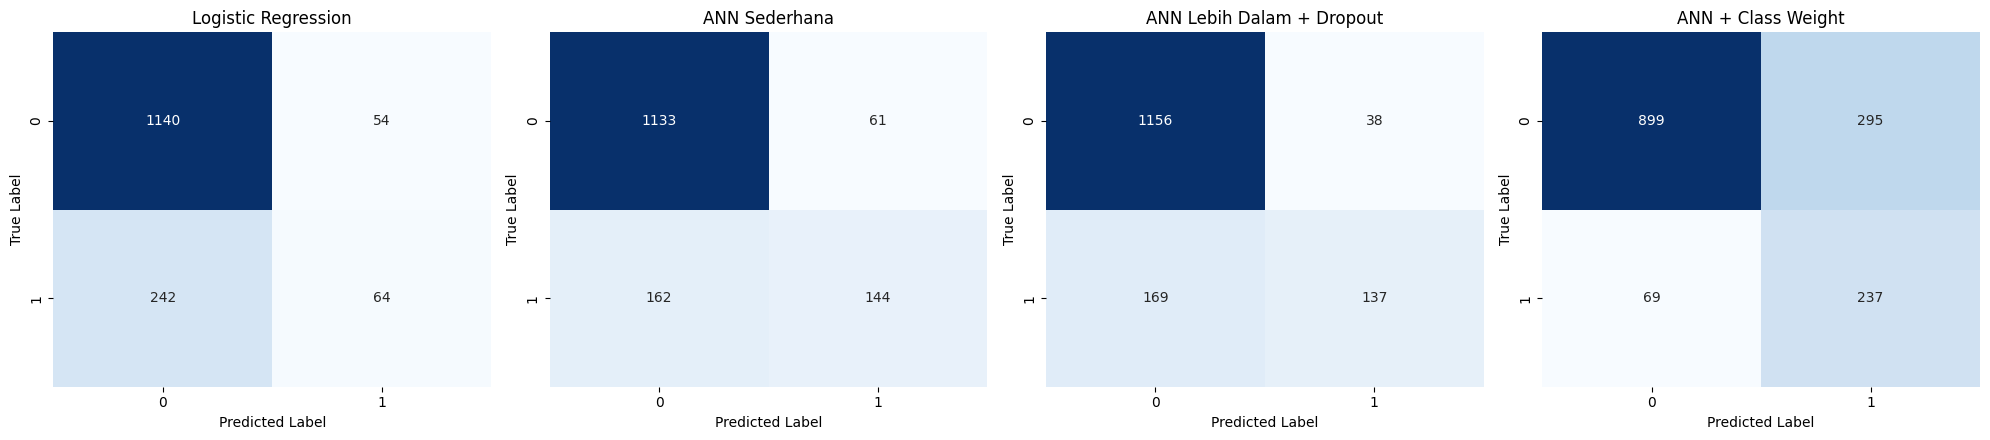

In [96]:
# Tampilkan Confusion Matrix setiap model dalam bentuk heatmap.
# Susun dalam satu baris subplot.
fig, axes = plt.subplots(1, 4, figsize=(20, 4.5))

models_dict = {
    "Logistic Regression": y_pred_lr,
    "ANN Sederhana": y_pred_simple,
    "ANN Lebih Dalam + Dropout": y_pred_deep,
    "ANN + Class Weight": y_pred_cw
}

for ax, (name, pred) in zip(axes, models_dict.items()):
    cm = confusion_matrix(y_test, pred)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=ax, cbar=False)
    ax.set_title(name)
    ax.set_xlabel("Predicted Label")
    ax.set_ylabel("True Label")

plt.tight_layout()
plt.show()

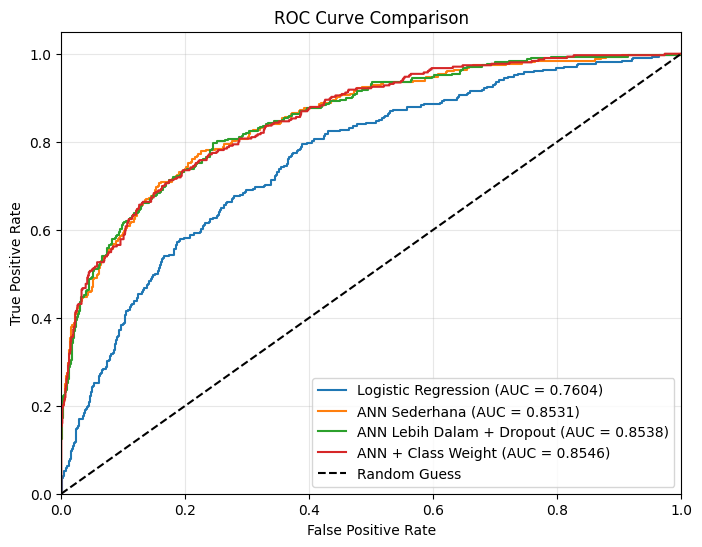

In [97]:
# Tampilkan ROC Curve seluruh model dalam satu plot beserta nilai AUC masing-masing.
plt.figure(figsize=(8, 6))

probas_dict = {
    "Logistic Regression": y_pred_proba_lr,
    "ANN Sederhana": y_pred_proba_simple,
    "ANN Lebih Dalam + Dropout": y_pred_proba_deep,
    "ANN + Class Weight": y_pred_proba_cw
}

for name, proba in probas_dict.items():
    fpr, tpr, _ = roc_curve(y_test, proba)
    roc_auc = auc(fpr, tpr)
    plt.plot(fpr, tpr, label=f"{name} (AUC = {roc_auc:.4f})")

plt.plot([0, 1], [0, 1], "k--", label="Random Guess")
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve Comparison")
plt.legend(loc="lower right")
plt.grid(True, alpha=0.3)
plt.show()

# 5. Analisis

Berdasarkan eksperimen klasifikasi churn nasabah bank, model baseline Logistic Regression menghasilkan akurasi sebesar 80.27 persen, precision 54.24 persen, recall 20.92 persen, F1 score 30.19 persen, dan AUC 0.7604. Performa ini kurang optimal karena recall yang rendah, dimana model hanya mampu mendeteksi sekitar 20.92 persen nasabah yang benar benar churn. Penggunaan Artificial Neural Network terbukti meningkatkan performa secara signifikan. ANN sederhana meningkatkan akurasi menjadi 85.53 persen, precision 73.06 persen, recall 46.08 persen, F1 score 56.51 persen, dan AUC 0.8538. Hal ini menunjukkan bahwa arsitektur jaringan saraf mampu menangkap hubungan non linear antar fitur tabular dengan lebih baik dibandingkan model linier.

Pada evaluasi learning curve, ANN sederhana menunjukkan konvergensi yang stabil antara train loss dan validation loss tanpa indikasi overfitting. Ketika arsitektur diperdalam menjadi dua hidden layer dengan penambahan Dropout 0.2, akurasi naik menjadi 86.07 persen dan precision meningkat secara mencolok mencapai 80.12 persen. Kurva validation loss pada ANN lebih dalam berada sedikit di bawah train loss. Hal ini terjadi karena Dropout mematikan 20 persen neuron secara acak selama pelatihan untuk mencegah ketergantungan antar neuron, sedangkan saat evaluasi validasi seluruh neuron aktif penuh. Penambahan layer dan Dropout terbukti mampu mempertahankan generalisasi model tetap optimal tanpa mengalami overfitting maupun underfitting.

Penanganan imbalanced data menggunakan class weight memberikan perubahan pola prediksi yang signifikan pada kelas minoritas churn. Model ANN dengan class weight berhasil meningkatkan recall kelas churn secara drastis dari 42.16 persen menjadi 78.43 persen, dengan F1 score tertinggi sebesar 57.35 persen dan AUC sebesar 0.8544. Peningkatan recall ini berdampak pada penurunan precision menjadi 45.20 persen dan akurasi keseluruhan menjadi 76.20 persen karena model menjadi lebih sensitif dalam menebak nasabah sebagai churn. Dalam konteks bisnis perbankan, peningkatan recall sangat krusial karena biaya kehilangan nasabah churn jauh lebih besar daripada memberikan penawaran retensi kepada nasabah yang sebenarnya tidak churn.



# 6. Kesimpulan dan Saran

Kesimpulan dari eksperimen memprediksi customer churn menunjukkan bahwa model Artificial Neural Network unggul secara signifikan dibandingkan Logistic Regression. Model ANN lebih dalam dengan Dropout menghasilkan tingkat akurasi dan precision tertinggi, sedangkan model ANN dengan class weight memberikan performa seimbang terbaik untuk mendeteksi nasabah churn dengan pencapaian recall dan F1 score tertinggi. Penerapan class weight terbukti efektif mengatasi kendala imbalanced dataset tanpa perlu melakukan manipulasi data sintetis.

Saran untuk eksperimen selanjutnya yaitu dilakukan tuning threshold probabilitas keputusan agar tercapai titik temu optimal antara precision dan recall. Selain itu, teknik penanganan imbalanced data lain seperti SMOTE atau Focal Loss dapat diuji untuk membandingkan efektivitasnya terhadap class weight. Penggunaan arsitektur seperti TabNet atau ensemble tree seperti XGBoost dan LightGBM juga disarankan sebagai pembanding tambahan pada dataset tabular.